In [ ]:
# Imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from features import add_derived, LABEL, HEURISTIC, POOL, cols
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.linear_model import lars_path
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, MissingIndicator
from sklearn.linear_model import LassoCV
from sklearn.model_selection import KFold

### We begin by reading all of our columns/data in and prepare our folds:

In [248]:
# Set seed
SEED = 6021

# Add feature engineered columns (MARINE_N3, Natural_Sugar, Legumes, F_Whole, Veg_Other_NS) based on EDA
df = add_derived(pd.read_csv("data/processed/analytic_cohort.csv"))

# Transform MET in accordance with EDA
# Log Transform + Activity indicator 
df["LOG_MET"] = np.log1p(df["MET_MIN_WK"])
df["ANY_PA"] = (df["MET_MIN_WK"] > 0).astype(float).where(df["MET_MIN_WK"].notna())

# Isolate HbA1C, make sure none of outcomes are missing
y = df["LBXGH"]
assert y.notna().all()

# Isolate controls by type
CTRL_NUM = ["RIDAGEYR", "INDFMPIR", "LOG_MET", "ANY_PA", "SED_MIN"]
CTRL_CAT = ["RIAGENDR", "RIDRETH3", "DMDEDUC2", "SMOKING", "FSDHH"]

# Isolate feature sets for each model
# Check that sizes match
POOL_COLS = cols(POOL)
SETS = {
    "B0": [],
    "Label": ["KCAL"] + cols(LABEL),
    "Heuristic": ["KCAL"] + cols(HEURISTIC),
    "B1": ["KCAL"] + cols(POOL),
}
assert all(len(SETS[s]) == 14 for s in ["Label", "Heuristic"]) and len(SETS["B1"]) == 84

# Read in feature costs, make a column vector containing them
# Also check that pool is a subset of the costs
cost = pd.read_csv("data/processed/discursive_cost.csv", index_col="feature")["cost"]
assert set(POOL) <= set(cost.index)

# Create an hba1c bin group to stratify the data
# Create and assign data to folds
hba1c_group = pd.cut(y, bins=[-np.inf, 5.7, 6.5, np.inf], right=False, labels=["normal", "pre", "high"])
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
df["FOLD"] = -1
for k, (_, test) in enumerate(outer.split(df, hba1c_group)):
    df.loc[df.index[test], "FOLD"] = k

# Output summary
print(df.shape)
print(pd.crosstab(df["FOLD"], hba1c_group))

(3286, 315)
LBXGH  normal  pre  high
FOLD                    
0         425  209    24
1         425  209    23
2         425  209    23
3         425  209    23
4         424  209    24


### Here are some reusable functions for the preprocessing, model making, and model predicting, which will be repeated many times:

In [249]:
ALPHAS = np.logspace(-3, 4, 60)
IMPUTE = "iterative"

def make_preprocessor(diet_cols):
    # Extract dietary columns
    diet_p1k = [c for c in diet_cols if c != "KCAL"]

    # Simple imputation of numeric columns with missing values
    if IMPUTE == "simple":
        # Isolate remaining numeric controls other than income
        num_other = [c for c in CTRL_NUM if c != "INDFMPIR"]

        # Apply simple median imputation+standardization for income
        # Apply simple median imputation for remaining numeric columns
        # One hot encode control cateogrical, fill with most frequent
        parts = [
            ("income", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), ["INDFMPIR"]),
            ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_other),
            ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                  OneHotEncoder(drop="first", handle_unknown="ignore")), CTRL_CAT),
        ]

    # Iterative imputation of numeric columns with missing values
    else:

        # encode step
        # keep numeric controls as they are, make a missing indicator for income, and simple impute cateogrical + OHE
        encode = ColumnTransformer([
            ("num", "passthrough", CTRL_NUM),
            ("miss", MissingIndicator(features="all"), ["INDFMPIR"]),
            ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                  OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)), CTRL_CAT),
        ], sparse_threshold=0)

        # With encoding complete, perform iterative imputation + standardization
        controls = Pipeline([("encode", encode),
                             ("impute", IterativeImputer(max_iter=10, random_state=SEED)),
                             ("scale", StandardScaler())])

        # Package entire pipeline for controls
        parts = [("controls", controls, CTRL_NUM + CTRL_CAT)]
    
    # Deal with diet_cols
    # Scale KCAL separately, doesn't need to be log transformed
    if "KCAL" in diet_cols:
        parts.append(("kcal", StandardScaler(), ["KCAL"]))

    # For remaining dietary predictors, log transform + standardize
    if diet_p1k:
        parts.append(("diet", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
                                            StandardScaler()), diet_p1k))

    return ColumnTransformer(parts, sparse_threshold=0)

def make_model(diet_cols, method):
    # Select regression method
    reg = LinearRegression() if method == "ols" else RidgeCV(alphas=ALPHAS)

    # Output model pipeline
    return Pipeline([("prep", make_preprocessor(diet_cols)), ("reg", reg)])

def oof_predict(data, target, diet_cols, method):
    # Initialize an empty pred vector
    pred = np.zeros(len(data))

    # For each fold
    for f in range(5):
        # Isolate train and test
        train, test = data["FOLD"] != f, data["FOLD"] == f

        # Make the model, fit on the training data
        model = make_model(diet_cols, method).fit(data[train], target[train])

        # Predict on test
        pred[test.to_numpy()] = model.predict(data[test])

    # Return prediction vectors
    return pred

### Another set of resuable functions needed for fitting the feature-selected model, including residualization and feature identification:

In [250]:
def residualized(train_df, y_train):
    # Preprocess controls + dietary features
    Z = make_preprocessor(["KCAL"]).fit_transform(train_df)
    D = StandardScaler().fit_transform(np.log1p(train_df[POOL_COLS]))

    # Compute diet residuals
    Dr = StandardScaler().fit_transform(D - LinearRegression().fit(Z, D).predict(Z))

    # Compute outcome residuals
    yr = y_train.to_numpy() - LinearRegression().fit(Z, y_train).predict(Z)

    # Return residuals
    return Dr, yr

def path_selections(Dr, yr, k_values, weights=None):
    # Set lasso weighting
    # If weights not specified, perform standard lasso for each 
    w = np.ones(Dr.shape[1]) if weights is None else np.asarray(weights, dtype=float)
    _, _, coefs = lars_path(Dr / w, yr, method="lasso")

    # Compute total non-zero coefficients
    n_active = (coefs != 0).sum(axis=0)

    # Initialize an output dictionary
    out = {}

    # For each k value
    for k in k_values:

        # atleast k features was kept in one model
        if (n_active >= k).any():
            # Take first occurence
            step = np.argmax(n_active >= k)

            # Record used features
            out[k] = [POOL_COLS[j] for j in np.flatnonzero(coefs[:, step])]

    return out

def run_outcome(data, target, k=13):
    # Fit fixed models
    res = {}
    for name, diet_cols in SETS.items():
        for method in ["ols", "ridge"]:
            res[(name, method)] = oof_predict(data, target, diet_cols, method)

    # Fit the k-feature selected model
    sel = {}
    res[("Selected", "ridge")] = np.zeros(len(data))
    for f in range(5):
        train, test = data["FOLD"] != f, data["FOLD"] == f
        Dr, yr = residualized(data[train], target[train])
        sel[f] = path_selections(Dr, yr, [k])[k]
        model = make_model(["KCAL"] + sel[f], "ridge").fit(data[train], target[train])
        res[("Selected", "ridge")][test.to_numpy()] = model.predict(data[test])
    return res, sel

## These functions are related to validating performance for the nested knee procedure

In [251]:
def nested_knee(data, target, k=13, tol=0.01):
    pred = np.zeros(len(data))
    chosen = []
    for f in range(5):
        train, test = data["FOLD"] != f, data["FOLD"] == f

        # Outer training data, re-split into its own 5 inner folds
        inner = data[train].reset_index(drop=True).copy()
        y_in = target[train].reset_index(drop=True)
        inner["FOLD"] = -1
        for i, (_, idx) in enumerate(KFold(5, shuffle=True, random_state=SEED).split(inner)):
            inner.loc[idx, "FOLD"] = i

        # Full frontier and knee rule using the outer training data only
        b0_in = oof_predict(inner, y_in, [], "ridge")
        front_in, _ = frontier(inner, y_in, b0_in, k=k)
        g = find_knee(front_in, tol=tol).name

        # Refit at that gamma on the whole outer training data, predict the held-out fold
        Dr, yr = residualized(data[train], target[train])
        feats = path_selections(Dr, yr, [k], weights=1 + g * w_cost)[k]
        model = make_model(["KCAL"] + feats, "ridge").fit(data[train], target[train])
        pred[test.to_numpy()] = model.predict(data[test])

        chosen.append({"fold": f, "gamma": g,
                       "cost": cost[[c.removesuffix("_P1K") for c in feats]].sum()})
    return pred, pd.DataFrame(chosen)

### These are functions needed for the threshold criteria of an outcome and predictive analysis

In [252]:
# Signal check on our outcome
def lasso_cv_oof(data, target):
    # Make a prediction vector
    pred = np.zeros(len(data))

    # Comptue features retained
    n_feats = []

    # Fix a fold
    for f in range(5):
        # Isolate train and test
        train, test = data["FOLD"] != f, data["FOLD"] == f

        # Residualize, perform lasso to select features
        Dr, yr = residualized(data[train], target[train])
        lasso = LassoCV(cv=5, random_state=SEED).fit(Dr, yr)
        feats = [POOL_COLS[j] for j in np.flatnonzero(lasso.coef_)]
        n_feats.append(len(feats))

        # Make model using ridge + test
        model = make_model(["KCAL"] + feats, "ridge").fit(data[train], target[train])
        pred[test.to_numpy()] = model.predict(data[test])

    # Return results
    return pred, n_feats


def delta_r2_curve(target, preds, base, n_boot=1000, seed=SEED):
    # Compute target variance
    t = target.to_numpy()
    v = t.var()

    # Compute bootstrap indices, initialize a rows
    idx = np.random.default_rng(seed).integers(0, len(t), (n_boot, len(t)))
    rows = []

    # Fix a model being evaluated
    for name, p in preds.items():
        # Compute MSE difference
        # Paired differences
        d = (t - base) ** 2 - (t - p) ** 2

        # Compute R^2 for each bootstrap
        boot = d[idx].mean(axis=1) / v

        # Output point estimate, CI
        rows.append({"k": name, "dR2": d.mean() / v,
                     "lo": np.percentile(boot, 2.5), "hi": np.percentile(boot, 97.5)})

    # Output results
    return pd.DataFrame(rows).set_index("k")

### These functions are for model comparison

In [253]:
# Compute bootstraps on paired R^2 to see if the models perform signficantly different 
def boot_diff(a, b, n=2000):
    # Difference vector, make it a numpy array
    d = (y - oof[a]) ** 2 - (y - oof[b]) ** 2
    d = d.to_numpy()

    # Bootstrap means
    means = [rng.choice(d, len(d)).mean() for _ in range(n)]

    # Return point estimate of the difference in R^2, along with the percentile interval
    return d.mean() / var_y, np.percentile(means, [2.5, 97.5]) / var_y

def comparison_table(target, models, ref):
    # Compare every other model against the reference
    others = {name: p for name, p in models.items() if name != ref}
    t = delta_r2_curve(target, others, models[ref])
    t.index.name = "model"

    # Read the paired interval: entirely above 0, entirely below 0, or neither
    t["result"] = np.where(t["lo"] > 0, "better", np.where(t["hi"] < 0, "worse", "no clear difference"))
    return t.sort_values("dR2", ascending=False).round(4)

def raw_table(target, models):
    t = target.to_numpy()
    rows = []

    # For each model
    for name, p in models.items():
        # Compute residuals, display R^2, MAE, RMSE
        e = t - p
        rows.append({"model": name, "R2": 1 - np.mean(e ** 2) / t.var(),
                     "RMSE": np.sqrt(np.mean(e ** 2)), "MAE": np.mean(np.abs(e))})
    return pd.DataFrame(rows).set_index("model").round(4)


def plot_comparisons(target, models, order, title):
    # Construct two different subplots 
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
    y = np.arange(len(order))[::-1]

    # For each figure
    for ax, ref, panel in zip(axes, ["B0 (control baseline) | 0 features", "FDA label | 13 features"], ["vs baseline (B0)", "vs FDA label"]):
        # Construct comparison table
        t = comparison_table(target, models, ref).reindex(order)

        # Plot each row in table
        for yi, (name, row) in zip(y, t.iterrows()):
            if name == ref:
                ax.text(0, yi, "reference", ha="left", va="center", fontsize=9, color="#777777")
                continue
            color = "#3B6EA8" if row["lo"] > 0 else ("#D55E00" if row["hi"] < 0 else "#777777")
            ax.plot([row["lo"], row["hi"]], [yi, yi], color=color, linewidth=2)
            ax.plot(row["dR2"], yi, "o", color=color, markersize=7)

        # Formatting
        ax.axvline(0, color="#444444", linewidth=1)
        ax.set_title(panel, fontsize=11)
        ax.set_xlabel("Out-of-fold ΔR² (95% paired interval)")
        ax.grid(axis="x", color="#E5E5E5", linewidth=0.6)
        ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    axes[0].set_yticks(y)
    axes[0].set_yticklabels(order)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

def plot_raw(target, models, order, title):
    # Isolate out of fold performance of each table
    r2 = raw_table(target, models)["R2"].reindex(order)

    # Isolate base R^2
    base = r2.iloc[0]

    # Denote gain of each model
    gain = (r2 - base).clip(lower=0)

    y = np.arange(len(order))[::-1]

    # Plot each bar with overlapped base
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.barh(y, [base] * len(order), color="#BBBBBB", edgecolor="white", linewidth=2,
            label="Explained by controls (B0)")
    ax.barh(y, gain, left=base, color="#3B6EA8", edgecolor="white", linewidth=2,
            label="Added by diet features")

    # Place label for each bar
    for yi, v in zip(y, r2):
        ax.text(v + 0.002, yi, f"{v:.3f}", va="center", fontsize=9, color="#444444")

    # Formatting
    ax.set_yticks(y)
    ax.set_yticklabels(order)
    ax.set_xlim(0, r2.max() * 1.12)
    ax.set_xlabel("Out-of-fold R²")
    ax.set_title(title, pad=14)
    ax.legend(frameon=False, fontsize=9, loc="center", bbox_to_anchor=(0.5, 1.0), ncol=2)
    ax.grid(axis="x", color="#E5E5E5", linewidth=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    fig.tight_layout()
    plt.show()

### These functions are used for the plotting of the predictive capacity curve

In [254]:
def size_curve(data, target, k_max=83, method="ridge", weights=None):
    sets_by_fold = []

    # Fix fold to hold out
    for f in range(5):
        # Isolate training data
        train = data["FOLD"] != f

        # Residualize
        Dr, yr = residualized(data[train], target[train])

        # Run lasso path once for every k from 1 to 83
        # For each fold dictionary of feature count --> features
        sets_by_fold.append(path_selections(Dr, yr, range(1, k_max + 1), weights))

    # Keep only k counts that all folds have
    ks = sorted(set.intersection(*(set(s) for s in sets_by_fold)))

    # Empty prediction array for each k
    pred = {k: np.zeros(len(data)) for k in ks}

    # Hold out each fold
    for f, sets in enumerate(sets_by_fold):
        # Isolate data
        train, test = data["FOLD"] != f, data["FOLD"] == f

        # For each shared k
        for k in ks:
            # Make model based on fixed k features selected in lasso
            model = make_model(["KCAL"] + sets[k], method).fit(data[train], target[train])

            # Populate test performance
            pred[k][test.to_numpy()] = model.predict(data[test])
    
    return pred, sets_by_fold


# Self-explanatory labeling + plotting
# Plot style for the fixed models: color, marker, legend name, number of diet features
STYLE = {"B0": ("#444444", "o", "Baseline B0", 0),
         "Label": ("#D55E00", "s", "FDA label", 13),
         "Heuristic": ("#009E73", "D", "Heuristic", 13),
         "Selected": ("#1F3F66", "^", "Selected (γ = 0)", 13)}

def plot_curve(target, curve_pred, fixed, ref, title):
    # Pair the curve against the reference model
    curve = delta_r2_curve(target, curve_pred, fixed[ref])

    # Selected-set curve with its paired band
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.fill_between(curve.index, curve["lo"], curve["hi"], color="#3B6EA8", alpha=0.15, linewidth=0,
                    label="Selected set, 95% interval")
    ax.plot(curve.index, curve["dR2"], color="#3B6EA8", linewidth=2, label="Selected set (k features)")

    # Reference model as the zero line
    color, _, name, _ = STYLE[ref]
    ax.axhline(0, color=color, linewidth=1.2, linestyle="--", label=f"{name} (reference)")

    ax.set_xlim(1, curve.index.max())
    ax.set_xlabel("Number of selected diet features (k)")
    ax.set_ylabel(f"Out-of-fold ΔR² vs {STYLE[ref][2]}")
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=9, loc="upper right")
    ax.grid(axis="y", color="#E5E5E5", linewidth=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    fig.tight_layout()
    plt.show()
    
    return curve

### These functions are used for the frontier trade-off curve

In [255]:
def frontier(data, target, base_pred, k=13):
    # Compute the residuals for each fold, as well as all of the data
    resid_by_fold = []
    for f in range(5):
        train = data["FOLD"] != f
        resid_by_fold.append(residualized(data[train], target[train]))
    Dr_all, yr_all = residualized(data, target)

    # Fix gamma 
    preds, rows = {}, []
    for g in GAMMAS:
        # Compute weights, initialize fold costs and prediction vector
        w = 1 + g * w_cost
        pred = np.zeros(len(data))
        fold_costs = []

        # Iterate through folds, construct model + perform prediction on held out
        for f, (Dr, yr) in enumerate(resid_by_fold):
            train, test = data["FOLD"] != f, data["FOLD"] == f
            feats = path_selections(Dr, yr, [k], weights=w)[k]
            fold_costs.append(cost[[c.removesuffix("_P1K") for c in feats]].sum())
            model = make_model(["KCAL"] + feats, "ridge").fit(data[train], target[train])
            pred[test.to_numpy()] = model.predict(data[test])

        # Compute on all training data to identify final set of features
        full = [c.removesuffix("_P1K") for c in path_selections(Dr_all, yr_all, [k], weights=w)[k]]

        # Store prediction vector for gamma
        preds[g] = pred

        # Row output: gamma, average cost across all folds, full cost on the full fit, features
        rows.append({"gamma": g, "cost": np.mean(fold_costs), "full_cost": cost[full].sum(), "features": full})

    # Create a dataframe with results, gamma is identifier
    res = pd.DataFrame(rows).set_index("gamma")

    # Add predictive performance (relative to baseline) to dataframe
    res = res.join(delta_r2_curve(target, preds, base_pred))

    # Sort values by cost and change in R2 
    res = res.sort_values(["cost", "dR2"], ascending=[True, False])

    # A point is on frontier if it is more predictive than every point as cheap or cheaper
    res["on_front"] = res["dR2"] > res["dR2"].cummax().shift(fill_value=-np.inf)
    return res.sort_index(), preds

def find_knee(front, tol=0.01):
    top = front.loc[0, "dR2"]

    # Return least complicated label within 0.01 of the best change in R^2
    return front[front["on_front"] & (front["dR2"] >= top - tol)].sort_values("cost").iloc[0]

# Self-explanatory labeling + plotting
def plot_frontier(target, front, front_preds, fixed, ref, knee, title):
    # Re-pair every frontier point against the reference model
    # (the frontier itself does not change: the reference only shifts all points by a constant)
    f = front.drop(columns=["dR2", "lo", "hi"]).join(delta_r2_curve(target, front_preds, fixed[ref]))
    pts = f.sort_values("cost")
    fr = pts[pts["on_front"]]

    fig, ax = plt.subplots(figsize=(11, 5.5))

    # All gammas faintly, frontier points with paired intervals
    ax.scatter(pts["cost"], pts["dR2"], s=18, color="#3B6EA8", alpha=0.3, linewidths=0)
    ax.errorbar(fr["cost"], fr["dR2"], yerr=[fr["dR2"] - fr["lo"], fr["hi"] - fr["dR2"]],
                color="#3B6EA8", linewidth=2, marker="o", markersize=5, elinewidth=0.8, capsize=3,
                alpha=0.9, label="Frontier")
    ax.axhline(0, color=STYLE[ref][0], linewidth=1.2, linestyle="--")

    # Label and heuristic, paired against the reference
    others = {n: fixed[n] for n in ["Label", "Heuristic"] if n != ref}
    refs = delta_r2_curve(target, others, fixed[ref])

    # Pure-prediction selection (gamma = 0), already paired against the reference in f
    refs.loc["Selected"] = f.loc[0, ["dR2", "lo", "hi"]].to_numpy()

    # Each point's position on the discursive cost axis
    xs = {"Label": cost[LABEL].sum(), "Heuristic": cost[HEURISTIC].sum(), "Selected": f.loc[0, "cost"]}

    for n, x in xs.items():
        color, marker, name, _ = STYLE[n]

        # The reference model sits at 0 without an interval
        if n == ref:
            ax.plot(x, 0, marker, color=color, markersize=7, zorder=3, label=f"{name} (reference)")
            continue

        # Every other point with its paired interval against the reference
        est, lo, hi = refs.loc[n, "dR2"], refs.loc[n, "lo"], refs.loc[n, "hi"]
        ax.errorbar(x, est, yerr=[[est - lo], [hi - est]], fmt=marker, color=color,
                    markersize=7, elinewidth=1.2, capsize=3, zorder=3, label=name)

    # Knee, at its re-paired position
    kx, ky = f.loc[knee.name, "cost"], f.loc[knee.name, "dR2"]
    ax.scatter(kx, ky, s=140, facecolors="none", edgecolors="#111111", linewidths=1.2, zorder=4, label="Knee")

    # Labels, legend outside on the right, and styling
    ax.set_xlabel("Total discursive cost of the 13 features (average across fold selections)")
    ax.set_ylabel(f"Out-of-fold ΔR² vs {STYLE[ref][2]}")
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(1.01, 1))
    ax.grid(color="#E5E5E5", linewidth=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    fig.tight_layout()
    plt.show()

def print_swaps(front):
    # Previous feature
    prev = None

    # Iterate through cost in descending order
    for g, row in front.sort_values("cost", ascending=False).iterrows():

        # Isolate current features
        cur = set(row["features"])

        # Document what changed between two kept sets
        if prev is not None and cur != prev:
            print(f"γ {g:7.3f} | cost {row['full_cost']:>3} | out: {sorted(prev - cur)} | in: {sorted(cur - prev)}")

        # Set previous front to current for next iteration
        prev = cur

### These functions are used for coefficient interpretation

In [256]:
def fold_stability(data, target, full, weights=None, k=13):
    # Rerun the (weighted) selection in each training fold, record the k features
    fold_sets = []
    for f in range(5):
        train = data["FOLD"] != f
        Dr, yr = residualized(data[train], target[train])
        fold_sets.append({c.removesuffix("_P1K") for c in path_selections(Dr, yr, [k], weights=weights)[k]})

    # Count how often each feature was selected, with its cost, whether it is in the full-data label
    counts = pd.Series([c for s in fold_sets for c in s]).value_counts()
    return pd.DataFrame({"folds": counts, "cost": cost.reindex(counts.index),
                         "in_full": counts.index.isin(full)})

def full_fit_coefs(data, target, features):
    # Fit controls + calories + the label's features on all of the data
    m = make_model(["KCAL"] + cols(features), "ridge").fit(data, target)

    # Keep calorie and diet coefficients
    # Plain names and each feature's cost
    names = m.named_steps["prep"].get_feature_names_out()
    coef = pd.Series(m.named_steps["reg"].coef_, index=names)
    coef = coef[[n for n in names if n.startswith(("diet", "kcal"))]]
    coef.index = [n.split("__")[1].removesuffix("_P1K") for n in coef.index]
    return pd.DataFrame({"coef": coef, "cost": cost.reindex(coef.index)}).sort_values("coef").round(4)

# HBA1C Analysis

We first see how the HBA1C outcome looks. Recall that, before proceeding with analysis, we need to be sure that our outcomes have sufficient predictive capacity. Our selection crtieria requires that for a LassoCV, a 95% paired bootstrap CI should show a significant difference in predictive capacity. Ideally, we would also like to see predictor saturation that exceeds $3$.

## Does HBA1C meet predictive criteria?

In [257]:
# Make an out of fold dictionary
oof = {}

# Fix a feature set and model
for name, diet_cols in SETS.items():
    for method in ["ols", "ridge"]:

        # Return prediction vector
        oof[(name, method)] = oof_predict(df, y, diet_cols, method)

# For each model, compute MSE + R^2 for test data 
var_y = y.var(ddof=0)
results = pd.DataFrame([
    {"model": name, "method": method,
     "MSE": np.mean((y - p) ** 2), "R2": 1 - np.mean((y - p) ** 2) / var_y}
    for (name, method), p in oof.items()
]).round(4)
print(results.to_string(index=False))

    model method    MSE     R2
       B0    ols 0.3334 0.0879
       B0  ridge 0.3334 0.0878
    Label    ols 0.3312 0.0940
    Label  ridge 0.3312 0.0940
Heuristic    ols 0.3342 0.0858
Heuristic  ridge 0.3338 0.0867
       B1    ols 0.3376 0.0764
       B1  ridge 0.3332 0.0885


Off the jump, these numbers are concerning. The model baseline B0, which has no dietary features performs better (!) in both OLS and ridge compared to the kitchen sink model. This suggests that some sort of saturation point is hit far before 83 features. While the label slightly improves prediction, the gain is marginal (fixing the model, a gain of 0.006 at most); heuristic is worse than the baseline. We explore further and assess our exclusion criteria:

In [258]:
rng = np.random.default_rng(SEED)

# For each model combination, report the change in R^2 estimate + CI
for a, b in [(("B0", "ridge"), ("Label", "ridge")), (("B0", "ridge"), ("Heuristic", "ridge")),
             (("B0", "ridge"), ("B1", "ridge"))]:
    est, ci = boot_diff(a, b)
    print(f"{b[0]} vs {a[0]}: ΔR² {est:.4f}, 95% CI [{ci[0]:.4f}, {ci[1]:.4f}]")


# Consider performance excluding the high values
mask = y < 9
for (name, method), p in oof.items():
    if method == "ridge":
        print(f"{name:10s} MAE {np.mean(np.abs(y - p)):.4f}  "
              f"R² without ≥9: {1 - np.mean((y[mask] - p[mask]) ** 2) / y[mask].var(ddof=0):.4f}")

Label vs B0: ΔR² 0.0061, 95% CI [0.0009, 0.0115]
Heuristic vs B0: ΔR² -0.0011, 95% CI [-0.0065, 0.0043]
B1 vs B0: ΔR² 0.0006, 95% CI [-0.0083, 0.0099]
B0         MAE 0.3312  R² without ≥9: 0.1486
Label      MAE 0.3297  R² without ≥9: 0.1579
Heuristic  MAE 0.3318  R² without ≥9: 0.1488
B1         MAE 0.3336  R² without ≥9: 0.1432


In [259]:
# Compute out of fold performance for each fold + total features selected
oof[("LassoCV", "ridge")], n_lasso = lasso_cv_oof(df, y)

# Compute a pairwise difference on performance; get sample estimate, bootstrap CI
r = delta_r2_curve(y, {"LassoCV": oof[("LassoCV", "ridge")]}, oof[("B0", "ridge")])

# Display features per fold + results
print(f"Features per fold: {n_lasso}")
print(f"ΔR² vs B0: {r.loc['LassoCV', 'dR2']:.4f} [{r.loc['LassoCV', 'lo']:.4f}, {r.loc['LassoCV', 'hi']:.4f}]")

Features per fold: [5, 8, 6, 9, 10]
ΔR² vs B0: 0.0043 [-0.0055, 0.0136]


As seen above, the predictive performance (as measured in R^2) is not significantly different from the baseline, even when we allowed the model to learn the total number of features to keep with cross-validation. Thus, our evaluation criteria deems HBA1C as not containing sufficient predictive signal to proceed with this analysis. Still, it may be worth doing additional exploration to see how it failed. First, we can consider the predictors it usually selected for the 13 feature model: 

In [260]:
K = 13
selected = {}
for method in ["ols", "ridge"]:
    oof[("Selected", method)] = np.zeros(len(df))

# Fix a held out fold
for k in range(5):
    # Standard pipeline: Isolate 13 features using training data
    train, test = df["FOLD"] != k, df["FOLD"] == k
    Dr, yr = residualized(df[train], y[train])
    feats = path_selections(Dr, yr, [K])[K]

    # Record features
    selected[k] = feats

    # Compute performance on test data for ols and ridge
    for method in ["ols", "ridge"]:
        model = make_model(["KCAL"] + feats, method).fit(df[train], y[train])
        oof[("Selected", method)][test.to_numpy()] = model.predict(df[test])

# Display features selected for each fold along with frequencies
print("Features per fold:", [len(f) for f in selected.values()])
freq = pd.Series([f.removesuffix("_P1K") for fs in selected.values() for f in fs]).value_counts()
print("\nSelection frequency (out of 5 folds):")
print(freq.to_string())

# Compute each CI pair for baseline and selected, label and selected
for a, b in [(("B0", "ridge"), ("Selected", "ridge")), (("Label", "ridge"), ("Selected", "ridge"))]:
    est, ci = boot_diff(a, b)
    print(f"{b[0]} vs {a[0]}: ΔR² {est:.4f}, 95% CI [{ci[0]:.4f}, {ci[1]:.4f}]")

# Run on all data and identify features selected
Dr_all, yr_all = residualized(df, y)
final_13 = path_selections(Dr_all, yr_all, [K])[K]
print("\nFinal 13 (full data):", [f.removesuffix("_P1K") for f in final_13])

Features per fold: [13, 13, 13, 13, 13]

Selection frequency (out of 5 folds):
VB2                 5
MOIS                5
A_DRINKS            5
ATOA                4
V_DRKGR             4
G_REFINED           4
LYCO                3
LZ                  2
P184                2
ATOC                2
F_OTHER             2
G_WHOLE             2
FL_TOT_ANTHOCYAN    2
THEO                2
M201                2
V_STARCHY_OTHER     2
CALC                1
CAFF                1
PF_SEAFD_LOW        1
PF_SOY              1
D_YOGURT            1
PF_MEAT             1
PF_EGGS             1
VK                  1
SODI                1
V_REDOR_OTHER       1
D_CHEESE            1
FL_TOT_FLAVANONE    1
FF                  1
F_CITMLB            1
FL_TOT_ISOFLAV      1
POTA                1
SOLID_FATS          1
Selected vs B0: ΔR² -0.0019, 95% CI [-0.0119, 0.0079]
Selected vs Label: ΔR² -0.0080, 95% CI [-0.0160, -0.0003]

Final 13 (full data): ['ATOC', 'ATOA', 'LYCO', 'LZ', 'VB2', 'THEO', 'MOIS', 'M201'

The selected model performs reliably worse (though close to inconclusive) than than the 13 feature label, which suggests that even 13 predictors is probably too much and is mostly just capturing noise; any 13 feature set is going to more or less perform the same, so long as they can recover the smaller number of important signals. Of interesting note is the consistency of selection; we see that vitamin B2, alcoholic drinks, and water content are all consistently chosen across all folds. We can explore the label further under HbA1C:

In [261]:
# Isolate base model fit and all orginal MSE
base = oof[("Label", "ridge")]
base_mse = np.mean((y - base) ** 2)
rows = []

# For each label feature
for f in LABEL:
    # Re-make model without dropped feature
    p = oof_predict(df, y, ["KCAL"] + cols([g for g in LABEL if g != f]), "ridge")
    rows.append({"dropped": f, "ΔR² loss": (np.mean((y - p) ** 2) - base_mse) / var_y})
print(pd.DataFrame(rows).sort_values("ΔR² loss", ascending=False).round(4).to_string(index=False))

   dropped  ΔR² loss
      CARB    0.0069
      TFAT    0.0025
      PROT    0.0019
      SUGR    0.0004
      POTA    0.0003
      SFAT    0.0001
ADD_SUGARS   -0.0001
      CALC   -0.0001
      IRON   -0.0002
      FIBE   -0.0002
      CHOL   -0.0003
      SODI   -0.0006
        VD   -0.0007


In [262]:
# Predictor gorups 
groups = {
    "fats": ["TFAT", "SFAT", "CHOL"],
    "carbs": ["CARB", "SUGR", "ADD_SUGARS", "FIBE"],
    "micronutrients": ["SODI", "VD", "CALC", "IRON", "POTA"],
    "macros": ["CARB", "TFAT", "PROT"],
}

# Rows
rows = []

# Fix features to drop
for g, feats in groups.items():
    # Predict with remaining, output results
    p = oof_predict(df, y, ["KCAL"] + cols([f for f in LABEL if f not in feats]), "ridge")
    rows.append({"dropped": g, "ΔR² loss": (np.mean((y - p) ** 2) - base_mse) / var_y})
print(pd.DataFrame(rows).round(4).to_string(index=False))

       dropped  ΔR² loss
          fats    0.0047
         carbs    0.0079
micronutrients   -0.0019
        macros    0.0070


Here, we see that dropping single elements more or less does not change R^2 (exception being the macros); this means most of these nutrients are either picking up noise or they are still tracking signal but it is preserved in predictors in left-over features. Since a lot of these single elements can be tied to larger blocks, we can also consider dropping the entire blocks to see if R^2 loss is signficant. Agan, dropping macros and carbs appears to result in the largest loss in R^2, though these numbers are still relatively small. Generally, then, it seems like most predictors are picking up noise. We can confirm this by checking performance at various sizes of feature sets. 

In [263]:
# Compare feature selection at each k with baseline
# Also compare feature selection to other models
curve_pred, curve_sets = size_curve(df, y)
curve = delta_r2_curve(y, curve_pred, oof[("B0", "ridge")])
refs = delta_r2_curve(y, {m: oof[(m, "ridge")] for m in ["Label", "Heuristic", "B1", "Selected"]},
                      oof[("B0", "ridge")])

# Isolate number of features that predicted best
best = curve["dR2"].max()
print(f"Best: k = {curve['dR2'].idxmax()}, ΔR² {best:.4f}")
print(f"Saturation point (within 0.01 of best): k = {curve.index[curve['dR2'] >= best - 0.01].min()}")
print(f"Label-equivalent size: k = {curve.index[curve['dR2'] >= refs.loc['Label', 'dR2']].min()}")
print("First feature per fold:", [s[1][0].removesuffix("_P1K") for s in curve_sets])
print(curve.loc[[1, 2, 3, 5, 8, 13, 20, 30, 50]].round(4).to_string())

Best: k = 1, ΔR² 0.0117
Saturation point (within 0.01 of best): k = 1
Label-equivalent size: k = 1
First feature per fold: ['A_DRINKS', 'A_DRINKS', 'A_DRINKS', 'A_DRINKS', 'A_DRINKS']
       dR2      lo      hi
k                         
1   0.0117  0.0058  0.0175
2   0.0112  0.0041  0.0182
3   0.0095  0.0015  0.0171
5   0.0047 -0.0053  0.0137
8   0.0027 -0.0077  0.0116
13 -0.0019 -0.0118  0.0077
20 -0.0040 -0.0133  0.0058
30 -0.0030 -0.0118  0.0069
50 -0.0016 -0.0103  0.0078


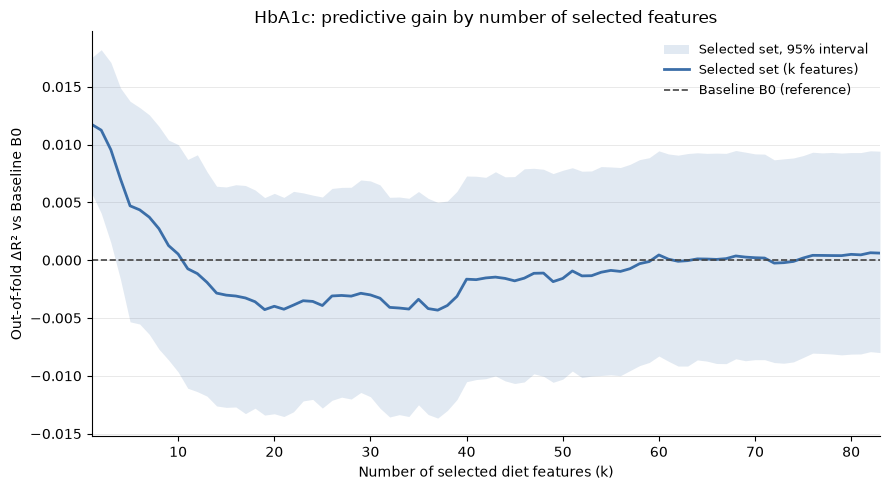

,dR2,lo,hi
k,,,
1,0.011741,0.005814,0.017503
2,0.011240,0.004054,0.018192
3,0.009549,0.001514,0.017098
4,0.007026,-0.001658,0.014891
5,0.004698,-0.005329,0.013738
...,...,...,...
79,0.000392,-0.008188,0.009259
80,0.000503,-0.008122,0.009304
81,0.000459,-0.008109,0.009304


In [264]:
# Plot predictive performances
fixed = {n: oof[(n, "ridge")] for n in ["B0", "Label", "Heuristic"]}
plot_curve(y, curve_pred, fixed, "B0", "HbA1c: predictive gain by number of selected features")

These results above all but confirm it. HbA1C is saturated by a single predictor, which is consistently alcohol. Alcohol is actualy found to slightly lower HBA1C levels in clinical studies, meaning that alcohol being slightly more predictive of HBA1C is not unsurprising. The rapid collapse of performance after including additional predictors implies that these predictors are just capturing noise. All in all, we should not proceed with HBA1C.

# Waist Height Ratio

For continuity's sake, WHR will use the exact same folds and cohort, even though the cohort was tailored to limit diabetes related confounding. Additional concerns for waist height ratio are dieting related, but, as disucssed earlier, we will choose to include these people in the larger analysis (in part because they are the type of people who will be using labels the most) and perform a supplementary analysis without them. 

In [265]:
# Isolate not na waist height ratio
dw = df[df["WHTR"].notna()].reset_index(drop=True)
yw = dw["WHTR"]
print(len(dw), pd.crosstab(dw["FOLD"], "n").T.to_string())

3196 FOLD     0    1    2    3    4
col_0                         
n      643  634  641  643  635


In [266]:
# Display summary of folds
print(dw.groupby("FOLD")["WHTR"].describe()[["count", "mean", "std", "min", "50%", "max"]].round(3))

      count   mean    std    min    50%    max
FOLD                                          
0     643.0  0.597  0.098  0.371  0.591  1.004
1     634.0  0.600  0.102  0.366  0.592  1.019
2     641.0  0.600  0.097  0.382  0.590  0.936
3     643.0  0.594  0.099  0.385  0.588  1.017
4     635.0  0.595  0.097  0.375  0.587  0.949


These distributions look more or less the same (what would be expected from a random split not stratified on anything). As such, we will proceed with analysis.

## Fixed Models and Prediction Curve

In [267]:
# Run the five fixed models (2 baselines, label, heuristic, feature-selected 13)
# oof_w stores their out of fold performance
# sel_w stores the selected predicts 
oof_w, sel_w = run_outcome(dw, yw)

# Identify variance for normalization
# Output each model's results
var_w = yw.var(ddof=0)
print(pd.DataFrame([
    {"model": n, "method": m, "R2": 1 - np.mean((yw - p) ** 2) / var_w}
    for (n, m), p in oof_w.items()
]).round(4).to_string(index=False))

print()

# Examine ridge out of fold performance compared to baseline
# First collect ridge predictions
ridge_w = {n: oof_w[(n, "ridge")] for n in ["Label", "Heuristic", "B1", "Selected"]}

# Express gain with respect to baseline
print(delta_r2_curve(yw, ridge_w, oof_w[("B0", "ridge")]).round(4).to_string())

print()

    model method     R2
       B0    ols 0.0983
       B0  ridge 0.0989
    Label    ols 0.1058
    Label  ridge 0.1067
Heuristic    ols 0.1085
Heuristic  ridge 0.1093
       B1    ols 0.1220
       B1  ridge 0.1298
 Selected  ridge 0.1337

              dR2      lo      hi
k                                
Label      0.0078  0.0006  0.0151
Heuristic  0.0104  0.0014  0.0187
B1         0.0309  0.0162  0.0450
Selected   0.0347  0.0203  0.0474



The preliminary analysis looks a fair bit stronger. R^2 is marginally higher across all models (as compared to HbA1C), which is what we expected. Moreover, there is a more definitive separation between B0 and the remaining models, especially the selected feature set. We can do some more investigation by constructing confidence intervals between each pair.

In [268]:
# For each pair, compute the 95 bootstrap for change in R^2
pairs = [("Label", "Selected"), ("Label", "Heuristic"), ("B1", "Selected")]
for a, b in pairs:
    r = delta_r2_curve(yw, {b: oof_w[(b, "ridge")]}, oof_w[(a, "ridge")])
    print(f"{b} vs {a}: ΔR² {r.loc[b, 'dR2']:.4f}  [{r.loc[b, 'lo']:.4f}, {r.loc[b, 'hi']:.4f}]")

Selected vs Label: ΔR² 0.0270  [0.0139, 0.0384]
Heuristic vs Label: ΔR² 0.0027  [-0.0068, 0.0115]
Selected vs B1: ΔR² 0.0038  [-0.0044, 0.0121]


This looks strong. However, we still need to meet the analysis criteria. Recall that our selection criteria requires that for a LassoCV + Ridge, a 95% paired bootstrap CI should show a significant difference in predictive capacity. Ideally, we would also like to see predictor saturation that exceeds $3$.

In [269]:
# Perform LassoCV and ridge, compute the paired difference bootstrap
oof_w[("LassoCV", "ridge")], n_lasso_w = lasso_cv_oof(dw, yw)
r = delta_r2_curve(yw, {"LassoCV": oof_w[("LassoCV", "ridge")]}, oof_w[("B0", "ridge")])
print(f"Features per fold: {n_lasso_w}")
print(f"ΔR² vs B0: {r.loc['LassoCV', 'dR2']:.4f} [{r.loc['LassoCV', 'lo']:.4f}, {r.loc['LassoCV', 'hi']:.4f}]")

Features per fold: [31, 30, 24, 31, 22]
ΔR² vs B0: 0.0313 [0.0156, 0.0465]


As we can see, we met both analysis criterias. First, the 95% bootstrap CI for change in R^2 is firmly positive, suggesting that there is a signficant difference in the predictive capacity of a feature selected model compared to the baseline. Unlike HbA1C, the selected number of features for each fold is about 27.8 on average. Based on this analysis, it appears that there is sufficient predictive signal contained in the diet features, and this predictive signal is distributed acrosss predictors. We can confirm this latter statement by considering the size curve:

In [270]:
# Compute size curve, identify best, compare fixed models + featured selected
# To baseline
curve_pred_w, curve_sets_w = size_curve(dw, yw)
curve_w = delta_r2_curve(yw, curve_pred_w, oof_w[("B0", "ridge")])
refs_w = delta_r2_curve(yw, ridge_w, oof_w[("B0", "ridge")])
best_w = curve_w["dR2"].max()

# Output summary statistics of the size curve
# Best k with greatest predictive capacity
# Saturation point --> Where curve begins to plateau
# First three features selected for each fold
print(f"Best: k = {curve_w['dR2'].idxmax()}, ΔR² {best_w:.4f}")
print(f"Saturation point: k = {curve_w.index[curve_w['dR2'] >= best_w - 0.01].min()}")
print("First 3 features per fold:", [[f.removesuffix("_P1K") for f in s[3]] for s in curve_sets_w])

Best: k = 13, ΔR² 0.0347
Saturation point: k = 7
First 3 features per fold: [['MOIS', 'PF_NUTSDS', 'FL_TOT_ANTHOCYAN'], ['POTA', 'MOIS', 'FL_TOT_ANTHOCYAN'], ['POTA', 'MOIS', 'FL_TOT_ANTHOCYAN'], ['MOIS', 'D_CHEESE', 'FL_TOT_ANTHOCYAN'], ['POTA', 'MOIS', 'FL_TOT_ANTHOCYAN']]


IMPORTANT: The associated intervals on this visual are paired differences with the baseline. These confidence intervals are valid to compare with the horizontal line 0, but comparing them with each other implicitly assumes observations are independent, even though each person in the data is represented in each estimate, and performance is positively correlated (individuals who are hard to predict for one model are generally hard to predict for the others). It can be shown that positive correlation decreases the spread of the sampling distribution as compared to case where samples are independent. So, while comparing these intervals is not wrong per se, their comparison is unfaithful and misrepresenting the actual comparison we want to make; in particular, they overstate the uncertainty by not accounting for correlation. 

With this in mind, we see that the FDA label actually inconclusively performs better than the baseline, the heursitic performs marginally better than the baseline, but all feature-selected models perform better than the baseline. In particular, the 13-feature selected model performs the best (which is interesting, given this was the number of nutrients on the FDA label). We see a steady increase in predictive capacity, which peaks at 13 features and steadily plateaus; the saturation point is about $7$ features. 

To assess each proposed model against the FDA label, we will produce the same visual but relative to the FDA. This will now provide a faithful way to compare each of our models to the FDA label, where the FDA label is the horizontal zero line. Most of the findings from the previous visual will remain more or less the same; the main goal is to visualize the confidence intervals relative to the label. 

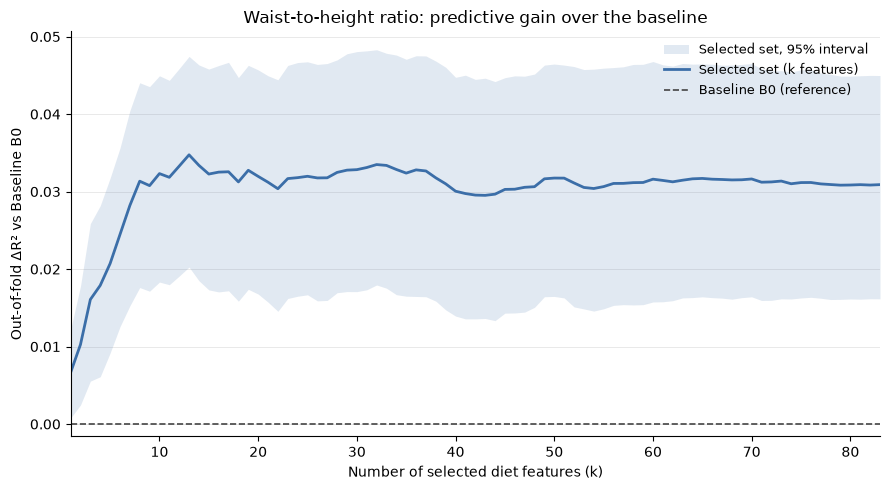

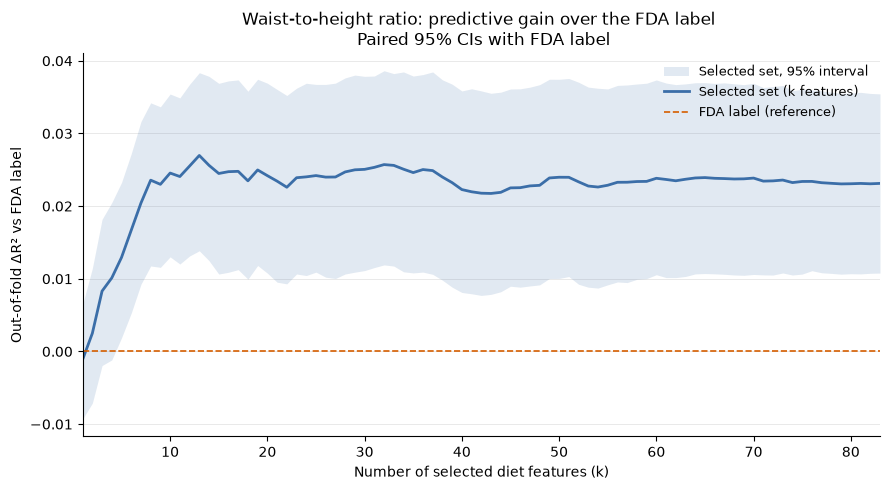

,dR2,lo,hi
k,,,
1,-0.001120,-0.009305,0.006459
2,0.002497,-0.007112,0.011440
3,0.008307,-0.001937,0.018189
4,0.010123,-0.001163,0.020486
5,0.012938,0.001874,0.023253
...,...,...,...
79,0.023060,0.010637,0.035524
80,0.023080,0.010699,0.035563
81,0.023126,0.010672,0.035662


In [271]:
# Output summary statistics of the size curve
# Best k with greatest predictive capacity
# Saturation point --> Where curve begins to plateau
# First three features selected for each fold
fixed_w = {n: oof_w[(n, "ridge")] for n in ["B0", "Label", "Heuristic"]}
plot_curve(yw, curve_pred_w, fixed_w, "B0", "Waist-to-height ratio: predictive gain over the baseline")
plot_curve(yw, curve_pred_w, fixed_w, "Label", "Waist-to-height ratio: predictive gain over the FDA label \n Paired 95% CIs with FDA label")

In [272]:
print(f"Saturation point: k = {curve_w.index[curve_w['dR2'] >= best_w - 0.01].min()}")
print("First 3 features per fold:", [[f.removesuffix("_P1K") for f in s[3]] for s in curve_sets_w])

Saturation point: k = 7
First 3 features per fold: [['MOIS', 'PF_NUTSDS', 'FL_TOT_ANTHOCYAN'], ['POTA', 'MOIS', 'FL_TOT_ANTHOCYAN'], ['POTA', 'MOIS', 'FL_TOT_ANTHOCYAN'], ['MOIS', 'D_CHEESE', 'FL_TOT_ANTHOCYAN'], ['POTA', 'MOIS', 'FL_TOT_ANTHOCYAN']]


Here, we see that the baseline performs marginally worse than the label, the heuristic performs about the same as the label, and the feature-selected models perform about the same as the label until about $5$ features, where the feature-selected model begins to perform signficantly better. Interestingly, the pointwise optimal is $13$ features, the exact number on the FDA label. However, the smallest model within the $0.01$ $R^2$ optimal point is $k = 7$. 

## Frontier

Now, we will move to the frontier.

In [273]:
# Test a range of gammas from 0 to 100 (evenly space on logscale)
GAMMAS = np.concatenate([[0], np.logspace(-2, 2, 30)])

# Order discursive costs by pool order
w_cost = cost.reindex(POOL).to_numpy(dtype=float)

# Compute frontier
front_w, preds_w = frontier(dw, yw, oof_w[("B0", "ridge")])

# Isolate top performer
top = front_w.loc[0, "dR2"]

# Knee
knee = front_w[front_w["on_front"] & (front_w["dR2"] >= top - 0.01)].sort_values("cost").iloc[0]

# Output summaries of all-food, knee, label, and heuristic in terms of discursive cost
print(f"γ = 0: cost {front_w.loc[0, 'cost']:.1f}, ΔR² {top:.4f}")
print(f"Knee: γ = {knee.name:.3f}, cost {knee['cost']:.1f}, ΔR² {knee['dR2']:.4f}")
print(f"Label: cost {cost[LABEL].sum()}, ΔR² {refs_w.loc['Label', 'dR2']:.4f}")
print(f"Heuristic: cost {cost[HEURISTIC].sum()}, ΔR² {refs_w.loc['Heuristic', 'dR2']:.4f}")

γ = 0: cost 27.8, ΔR² 0.0347
Knee: γ = 1.610, cost 3.6, ΔR² 0.0278
Label: cost 26, ΔR² 0.0078
Heuristic: cost 9, ΔR² 0.0104


We can visualize the frontier:

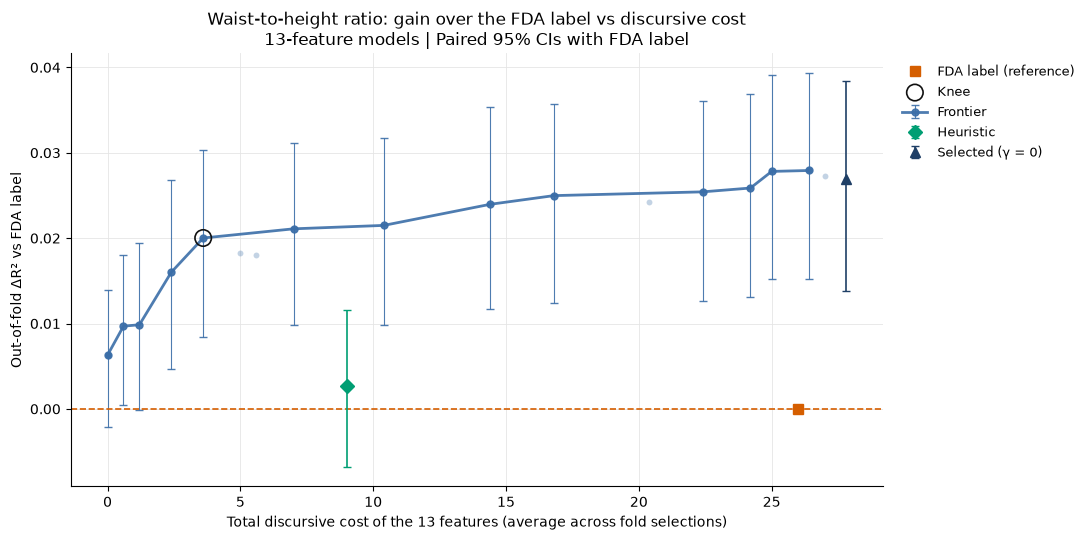

γ   0.092 | cost  23 | out: ['ATOA'] | in: ['PF_SOY']
γ   0.174 | cost  20 | out: ['FL_TOT_ISOFLAV', 'SFAT'] | in: ['ATOA', 'V_REDOR_OTHER']
γ   0.240 | cost  17 | out: ['ATOA'] | in: ['F_CITMLB']
γ   0.452 | cost  13 | out: ['M201'] | in: ['V_OTHER']
γ   0.621 | cost   6 | out: ['FL_APIGEN', 'FL_TOT_ANTHOCYAN'] | in: ['OILS', 'PF_POULT']
γ   0.853 | cost   5 | out: ['OILS'] | in: ['F_OTHER']
γ   1.610 | cost   3 | out: ['POTA'] | in: ['PF_MEAT']
γ   3.039 | cost   0 | out: ['MOIS'] | in: ['D_MILK']


In [274]:
# Plot the frontier with the label, heuristic and knee
plot_frontier(yw, front_w, preds_w, fixed_w, "Label", knee,
              "Waist-to-height ratio: gain over the FDA label vs discursive cost\n13-feature models | Paired 95% CIs with FDA label")

# Show which features enter and leave as the complexity penalty rises
print_swaps(front_w)

These results are interesting. The shape of the frontier illustrates an initial and rapid increase in predictive performance, which begins to slow at a total discurive cost at approximately $3.4$; this is labeled as the knee. From here on out, predictive gains only modestly increase, even as average discursive cost grows quite large. The swaps do not appear so informative.

In [275]:
# Compute deltas with label
front_vl = front_w.drop(columns=["dR2", "lo", "hi"]).join(
    delta_r2_curve(yw, preds_w, oof_w[("Label", "ridge")]))

# Display all gamma performance (relative to label)
print(front_vl[["cost", "dR2", "lo", "hi", "on_front"]].round(4).to_string())

            cost     dR2      lo      hi  on_front
gamma                                             
0.000000    27.8  0.0270  0.0139  0.0384     False
0.010000    27.0  0.0273  0.0140  0.0390     False
0.013738    26.4  0.0279  0.0153  0.0393      True
0.018874    26.4  0.0279  0.0153  0.0393     False
0.025929    26.4  0.0279  0.0153  0.0393     False
0.035622    26.4  0.0279  0.0153  0.0393     False
0.048939    25.0  0.0278  0.0152  0.0392      True
0.067234    24.2  0.0259  0.0132  0.0369      True
0.092367    22.4  0.0254  0.0126  0.0361      True
0.126896    22.4  0.0254  0.0126  0.0361     False
0.174333    20.4  0.0243  0.0121  0.0354     False
0.239503    16.8  0.0250  0.0125  0.0357      True
0.329034    14.4  0.0240  0.0117  0.0354      True
0.452035    10.4  0.0215  0.0098  0.0317      True
0.621017     7.0  0.0211  0.0098  0.0311      True
0.853168     5.6  0.0180  0.0067  0.0286     False
1.172102     5.0  0.0182  0.0068  0.0290     False
1.610262     3.6  0.0200  0.008

Now, we can compare the knee to the other fixed models:

In [276]:
g_knee= knee.name
tests = [(g_knee, "Label"), (g_knee, "Heuristic"), (g_knee, "Selected")]
for g, ref in tests:
    r = delta_r2_curve(yw, {"x": preds_w[g]}, oof_w[(ref, "ridge")])
    print(f"γ {g:.3f} (cost {front_w.loc[g, 'cost']:.1f}) vs {ref}: "
          f"ΔR² {r.loc['x', 'dR2']:.4f}  [{r.loc['x', 'lo']:.4f}, {r.loc['x', 'hi']:.4f}]")

γ 1.610 (cost 3.6) vs Label: ΔR² 0.0200  [0.0085, 0.0303]
γ 1.610 (cost 3.6) vs Heuristic: ΔR² 0.0174  [0.0069, 0.0282]
γ 1.610 (cost 3.6) vs Selected: ΔR² -0.0070  [-0.0147, 0.0004]


## Coefficient Exploration

### All Prediction

In [277]:
# Full-data features of the pure-prediction label (gamma = 0)
full_sel = front_w.loc[0, "features"]
print("Features:", full_sel, "| total cost:", cost[full_sel].sum())

# How consistently each feature is selected across folds
print(fold_stability(dw, yw, full_sel).to_string())

# Coefficients from the full-data fit
print(full_fit_coefs(dw, yw, full_sel).to_string())

Features: ['SFAT', 'ATOA', 'POTA', 'MOIS', 'M201', 'V_DRKGR', 'PF_NUTSDS', 'D_YOGURT', 'D_CHEESE', 'A_DRINKS', 'FL_APIGEN', 'FL_TOT_ANTHOCYAN', 'FL_TOT_ISOFLAV'] | total cost: 26
                  folds  cost  in_full
PF_NUTSDS             5     0     True
FL_TOT_ANTHOCYAN      5     4     True
MOIS                  5     3     True
A_DRINKS              5     0     True
V_DRKGR               5     0     True
FL_APIGEN             5     4     True
M201                  5     4     True
POTA                  5     2     True
SFAT                  4     2     True
FL_TOT_ISOFLAV        4     4     True
D_YOGURT              4     0     True
D_CHEESE              3     0     True
P204                  2     4    False
ATOA                  2     3     True
VB6                   2     3    False
FL_QUERCE             1     4    False
VC                    1     3    False
VB2                   1     3    False
PF_SOY                1     0    False
                    coef  cost
A_DRINKS  

There are several things that stand out about this selected feature set, and we will walk down the line. First, the largest magnitude coefficient is MOIS, which is a complicated metric that essentially computes the total water consumption across drinks and food. While it isn't just drinking water, drinking water dominates the source of MOIS in this sample. Rather unintuively, the MOIS coefficient is positive, meaning more water is generally associated with larger waist height ratio. This seems counterintuitive; one would think more water is satiating, and, thus, people would eat less and have smaller waists. This runs into one of our first issues of cross-sectional design. In essence, the model is picking up that the people with the largest ratio tend to drink more water, but this additional water has not been the norm for this person. Rather, it is a concious change made as part of typical dieting advice. That is to say, many of these people with large waist height ratios are reporting drinking more water because it is recommended for losing weight; water helps satiate you. In this case, the model is picking up on reverse causation. 

A similar story is likely happening with the alcoholic drinks, which paradoxically shows a decrease in waist height ratio, but there is possibly three different factors at play here. First, since all coefficients are densities and KCAL is fixed in the model, reducing alcoholic drinks implies that calories from other food (monounaturated fats, proteins, all carbs) increases. The partial correlation displayed below shows that this is mostly carbohydrate (and mostly processed carbs at that). So, the coefficient should be interpreted as an alcohol-carbohydrate swap. In that light, alcohol can be viewed as a lesser of two evils; eating processed sugars is generally more correlated with weight gain than drinking alcohol. Another contribution worth discussing is that alcohol consumption is very ritualistic for non-alcoholics; moderate alcohol consumption can often be an indicator of a strong social life, and this trend persists across generations. Countless studies have demonstrated the benefits of social life on health outcomes in both direct and indirect ways. Finally, the sick quitters effect may be at play, where the worst alcohol offenders have since quit drinking due to a personal choice, a doctor's visit, or a concerned loved one. So, while the alcohol may have contributed to their current position, it does not show up in a cross-sectional study where dietary habits and health readings occur at the same time. On the other hand, the average consumer never drinks enough for there to be a problem and continues to do so. These people, who have closer to average waist height ratios, then reinforce this pattern.

A similar argument can be made for water content. Water is one of the most common and universally recommeded tools for weight loss. Those who are beginning diets or starting them often increase water intake. Along slightly different lines, there is pressure and often shame on those who struggle managing their weight to openly discuss their eating habits. This may lead to systematic underreporting or false reporting where items typically associated with lower weight are reported in an attempt to avoid judgement. 

Potassium and dark leafy greens produce an interesting combination. Dark leafy greens and dairy are some of the best sources of potassium, but since both were retained in the model, it seems the potassium was selected for a different reason; outside of greens and dairy, potassium is found largely in tomatoes, coffee, bananas, potatoes, sweet potatoes, and carrots. Many of these categories have their own sub-groups (such as red vegetables or starch potatoes) so it is likely they are all contributing to make the potassium signal stronger than a single group. 

Similarly, there are nuts and M201, which is a type of monounsaturated fat found mostly in nuts and processed oils. Since nuts are already in this label, this is more than likely tracking the oils (rapeseed, canola, etc.) and more broadly fried food consumption. 

Another interesting trio is the cheese, saturated fat, and yogurt. Notice that saturated fat is essentially negligible. How did this happen? Lasso selection tends to be very aggressive in shrinking predictors; even predictors with strong signal are shrunk partially. When saturated fat entered the model, it is likely the signal in cheese that overlapped had been shrunk out. When ridge goes to refit, the signal is originally restored, and saturated fat's signal largely becomes redudnant, though ridge still keeps some chips in. Still, the remaining coefficients, yogurt and cheese, point in different directions entirely. The key point is that yogurt and cheese both contain processed and unprocessed counterparts in their label, though this cohort disproportionately consumes less processed forms of yogurt and more processed forms of cheese; this is unsurprising as cheese forms are generally more processed than yogurt forms. So, cheese is probably picking up mainly on processed cheese forms found in unhealthy foods (see below), and yogurt is probably picking up mostly on the unprocessed forms (see below). Literature does show that unprocessed forms of dairy tend to have neutral or slightly beneficial health outcomes. 

Another group worth isolating is the three flavanoid groups: Apigenin, Anthocyanins, and Isoflavoenes. First, note that all of these groups had moderately sized coefficients in the final model fit, all of which were negative. Apigen is largely found in celery, lettuce, green tea, and parsley. Anthocyanins largely come from berries and stone fruits. Isoflavones generally tracks soy products but nutritional beverages capture about $46.5\%$ of isoflavone quantity in the cohort; nutrional beverages are generally supplied to those who are struggling to gain weight or older populations who are attempting to maintain muscle, so this is partially driven by reverse causation. No matter, despite making up only $12\%$ of the feature pool, they make up almost a quarter of the final label, and apigenin, antho, and iso are selected 5, 5, and 4 times across folds. This is high frequency, especially considering that there are moderately correlated alternatives. 

ATOA suffers a similar fate, where a large portion of the food is tracking nutritional beverages, bars, and powders; almost a fitness indicator?


In [278]:
FNDDS_PATH = "data/raw/2017_2018/2017-2018 FNDDS At A Glance - FNDDS Ingredients.xlsx"

# Food-level intake for the analytic cohort only, with every selected feature
foods = pd.read_csv("data/processed/foods_long.csv.gz", usecols=["SEQN", "FOODCODE"] + list(full_sel))
foods = foods[foods["SEQN"].isin(dw["SEQN"])]
n_people = foods["SEQN"].nunique()

# Food descriptions and WWEIA categories, one row per food code
desc = (pd.read_excel(FNDDS_PATH, header=1,
                      usecols=["Food code", "Main food description", "WWEIA Category description"])
        .drop_duplicates("Food code").set_index("Food code"))

def food_sources(feature, n=8):
    # Total intake of the feature from each food code, and its share of all intake
    by_food = foods.groupby("FOODCODE")[feature].sum()
    share = by_food / by_food.sum()

    # Share of cohort members who reported each food at least once
    eaten = foods[foods[feature] > 0].groupby("FOODCODE")["SEQN"].nunique() / n_people

    top = pd.DataFrame({"share of intake": share, "% of people eating": eaten}).nlargest(n, "share of intake")
    top.index = desc["Main food description"].reindex(top.index).fillna("(no description)")

    # The same intake summed by WWEIA category
    cats = (foods.assign(cat=foods["FOODCODE"].map(desc["WWEIA Category description"]))
            .groupby("cat")[feature].sum() / by_food.sum()).nlargest(5)
    return top.round(3), cats.round(3)

for feat in full_sel:
    top, cats = food_sources(feat)
    print(f"\n=== {feat} (cost {cost[feat]}) ===")
    print(top.to_string())
    print("Top categories:")
    print(cats.to_string())


=== SFAT (cost 2) ===
                        share of intake  % of people eating
Main food description                                      
Milk, whole                       0.022               0.160
Milk, reduced fat (2%)            0.015               0.167
Butter, stick                     0.015               0.092
Cheese, Cheddar                   0.012               0.080
Ice cream, vanilla                0.011               0.050
Mayonnaise, regular               0.009               0.189
Cheese, American                  0.009               0.094
Cheese, NFS                       0.008               0.088
Top categories:
cat
Cheese                   0.056
Burritos and tacos       0.044
Pizza                    0.043
Burgers (single code)    0.041
Eggs and omelets         0.041

=== ATOA (cost 3) ===
                                                               share of intake  % of people eating
Main food description                                                           

In [279]:
# Hold fixed everything the model holds fixed: controls + KCAL (preprocessed as in the models)
# and the other 12 features of the pure-prediction label
feats = [f for f in full_sel if f != "A_DRINKS"]
Zc = make_preprocessor(["KCAL"]).fit_transform(dw)
Z = np.column_stack([Zc, np.log1p(dw[cols(feats)])])

# Residualize: the part of a variable not explained by Z
resid = lambda v: v - LinearRegression().fit(Z, v).predict(Z)

# Alcohol density, log-transformed as in the model, adjusted
alc = resid(np.log1p(dw["A_DRINKS_P1K"]))

# Each macronutrient's percentage of energy, adjusted the same way, then correlated with adjusted alcohol
shares = {"carbohydrate": 4 * dw["CARB_P1K"] / 10, "protein": 4 * dw["PROT_P1K"] / 10,
          "fat": 9 * dw["TFAT_P1K"] / 10}
for name, s in shares.items():
    rho = pd.Series(alc).corr(pd.Series(resid(s)), method="spearman")
    print(f"{name:13s} ρ with alcohol (both adjusted) = {rho:.2f}")

carbohydrate  ρ with alcohol (both adjusted) = -0.50
protein       ρ with alcohol (both adjusted) = -0.03
fat           ρ with alcohol (both adjusted) = -0.09


In [280]:
for name, col in {"added sugars": "ADD_SUGARS_P1K", "refined grains": "G_REFINED_P1K",
                  "whole grains": "G_WHOLE_P1K", "fruit juice": "F_JUICE_P1K",
                  "potatoes": "V_STARCHY_POTATO_P1K"}.items():
    v = resid(np.log1p(dw[col]))
    print(f"{name:15s} ρ with alcohol (both adjusted) = {pd.Series(alc).corr(pd.Series(v), method='spearman'):.2f}")

added sugars    ρ with alcohol (both adjusted) = -0.24
refined grains  ρ with alcohol (both adjusted) = -0.21
whole grains    ρ with alcohol (both adjusted) = -0.07
fruit juice     ρ with alcohol (both adjusted) = -0.02
potatoes        ρ with alcohol (both adjusted) = -0.01


### Knee

In [281]:
# Full-data features of the knee label
full_knee = front_w.loc[g_knee, "features"]
print("Features:", full_knee, "| total cost:", cost[full_knee].sum())

# How consistently each feature is selected across folds, using the knee's penalty weights
print(fold_stability(dw, yw, full_knee, weights=1 + g_knee * w_cost).to_string())

# Coefficients from the full-data fit
print(full_fit_coefs(dw, yw, full_knee).to_string())

Features: ['MOIS', 'F_CITMLB', 'F_OTHER', 'V_DRKGR', 'V_REDOR_OTHER', 'V_OTHER', 'PF_MEAT', 'PF_POULT', 'PF_SOY', 'PF_NUTSDS', 'D_YOGURT', 'D_CHEESE', 'A_DRINKS'] | total cost: 3
                  folds  cost  in_full
PF_NUTSDS             5     0     True
V_REDOR_OTHER         5     0     True
MOIS                  5     3     True
A_DRINKS              5     0     True
V_DRKGR               5     0     True
PF_SOY                5     0     True
D_CHEESE              5     0     True
D_YOGURT              5     0     True
F_CITMLB              5     0     True
PF_POULT              4     0     True
F_OTHER               4     0     True
V_OTHER               3     0     True
PF_MEAT               2     0     True
D_MILK                2     0    False
OILS                  1     1    False
POTA                  1     2    False
LEGUMES               1     0    False
V_STARCHY_POTATO      1     0    False
V_REDOR_TOMATO        1     0    False
                 coef  cost
A_DRINKS     

In [282]:
feats_needed = sorted(set(full_sel) | set(full_knee))
foods = pd.read_csv("data/processed/foods_long.csv.gz", usecols=["SEQN", "FOODCODE"] + feats_needed)
foods = foods[foods["SEQN"].isin(dw["SEQN"])]

In [283]:
for feat in full_knee:
    top, cats = food_sources(feat)
    print(f"\n=== {feat} (cost {cost[feat]}) ===")
    print(top.to_string())
    print("Top categories:")
    print(cats.to_string())


=== MOIS (cost 3) ===
                                                    share of intake  % of people eating
Main food description                                                                  
Water, bottled, unsweetened                                   0.228               0.603
Water, tap                                                    0.205               0.541
Coffee, brewed                                                0.073               0.442
Soft drink, cola                                              0.022               0.187
Beer                                                          0.017               0.084
Milk, reduced fat (2%)                                        0.011               0.167
Soft drink, fruit flavored, caffeine free                     0.010               0.106
Tea, iced, brewed, black, pre-sweetened with sugar            0.010               0.070
Top categories:
cat
Bottled water    0.228
Tap water        0.205
Coffee           0.099
Tea     

Most of these results are pretty self-explanatory. There are three vegetable categories that essentially capture the entire range of vegetables (dark greens, red/orange veggies, and fall through/ambigous like avocado, cabbage, etc.), two fruit categories to capture all fruit, nuts, yogurt, soy, cheese, and meats (red and white). The trends match what you would anticipate for the most part, and they are relatively stable across folds (except for the other categories and red meat category). 

I will not repeat the discussion for many of the overlapping features from above. Soy is largely tracking the nutrition archetype/frail elderly discussed. The meat section is really complicated and highlights a bigger symbolic issue. While these coefficients are moderately positive, the decomposition highlights that both food groups are comprised of either very processed or very unprocessed forms, and even the food labeling scheme used by NHANES does not do a great job distinguishing at times; meat mixed dishes and beef, excludes ground, for instance are two categories that contain both processed and unprocessed variants. In this way, we are getting a sort of weighted average of their effects; we are pretty confident that processed meats are bad for you, but it is harder to say about unprocessed ones. 

## Model Summary

Here, we summarize the predictive performances of the six models of interest.

We begin by performing a more faithful evaluation of our knee model. That is, we chose the knee based on its relative predictive performance on the held-out data, so if we then reported this performance as its estimate, we are being overly optimistic. In reality, we should perform a nested CV, where the inner data repeats the knee procedure (which relies on an inner CV), and the outer assesses the chosen knee's performance.

In [ ]:
# Perform nested CV for knee, display its choices 
nested_pred, nested_choices = nested_knee(dw, yw)
print(nested_choices.round(3).to_string(index=False))

# Compare performance with paired CI
for ref in ["Label", "Heuristic"]:
    r = delta_r2_curve(yw, {"nested knee": nested_pred}, oof_w[(ref, "ridge")])
    print(f"Nested knee vs {ref}: ΔR² {r.loc['nested knee', 'dR2']:.4f}  "
          f"[{r.loc['nested knee', 'lo']:.4f}, {r.loc['nested knee', 'hi']:.4f}]")

 fold  gamma  cost
    0  0.092    27
    1  4.175     0
    2  1.172     9
    3  0.174    24
    4  1.172     3
Nested knee vs Label: ΔR² 0.0194  [0.0085, 0.0289]
Nested knee vs Heuristic: ΔR² 0.0168  [0.0060, 0.0269]


In [285]:
# Collect every WHtR model's out-of-fold predictions
models_w = {
    "B0 (control baseline) | 0 features": oof_w[("B0", "ridge")],
    "FDA label | 13 features": oof_w[("Label", "ridge")],
    "Heuristic (all discursion) | 13 features": oof_w[("Heuristic", "ridge")],
    "Feature Selected (all prediction) | 13 features": oof_w[("Selected", "ridge")],
    "Knee (frontier compromise) | 13 features": nested_pred,
    "B1 (ceiling baseline) | 83 features": oof_w[("B1", "ridge")]
}

In [286]:
order = list(models_w.keys())

In [287]:
print(raw_table(yw, models_w).reindex(order).to_string())

                                                     R2    RMSE     MAE
model                                                                  
B0 (control baseline) | 0 features               0.0989  0.0936  0.0733
FDA label | 13 features                          0.1067  0.0932  0.0728
Heuristic (all discursion) | 13 features         0.1093  0.0931  0.0728
Feature Selected (all prediction) | 13 features  0.1337  0.0918  0.0716
Knee (frontier compromise) | 13 features         0.1261  0.0922  0.0718
B1 (ceiling baseline) | 83 features              0.1298  0.0920  0.0717


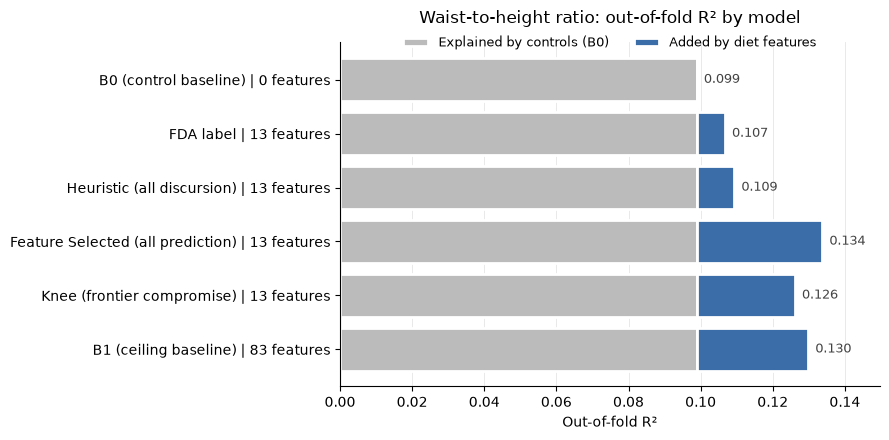

In [288]:
plot_raw(yw, models_w, order, "Waist-to-height ratio: out-of-fold R² by model")

In [289]:
# Compare each model against the baseline
print("WHtR: each model vs baseline (B0)")
print(comparison_table(yw, models_w, "B0 (control baseline) | 0 features").to_string())

WHtR: each model vs baseline (B0)
                                                    dR2      lo      hi  result
model                                                                          
Feature Selected (all prediction) | 13 features  0.0347  0.0203  0.0474  better
B1 (ceiling baseline) | 83 features              0.0309  0.0162  0.0450  better
Knee (frontier compromise) | 13 features         0.0272  0.0144  0.0381  better
Heuristic (all discursion) | 13 features         0.0104  0.0014  0.0187  better
FDA label | 13 features                          0.0078  0.0006  0.0151  better


In [290]:
# Compare each model against the label
print("\nWHtR: each model vs FDA label")
print(comparison_table(yw, models_w, "FDA label | 13 features").to_string())


WHtR: each model vs FDA label
                                                    dR2      lo      hi               result
model                                                                                       
Feature Selected (all prediction) | 13 features  0.0270  0.0139  0.0384               better
B1 (ceiling baseline) | 83 features              0.0231  0.0108  0.0354               better
Knee (frontier compromise) | 13 features         0.0194  0.0085  0.0289               better
Heuristic (all discursion) | 13 features         0.0027 -0.0068  0.0115  no clear difference
B0 (control baseline) | 0 features              -0.0078 -0.0151 -0.0006                worse


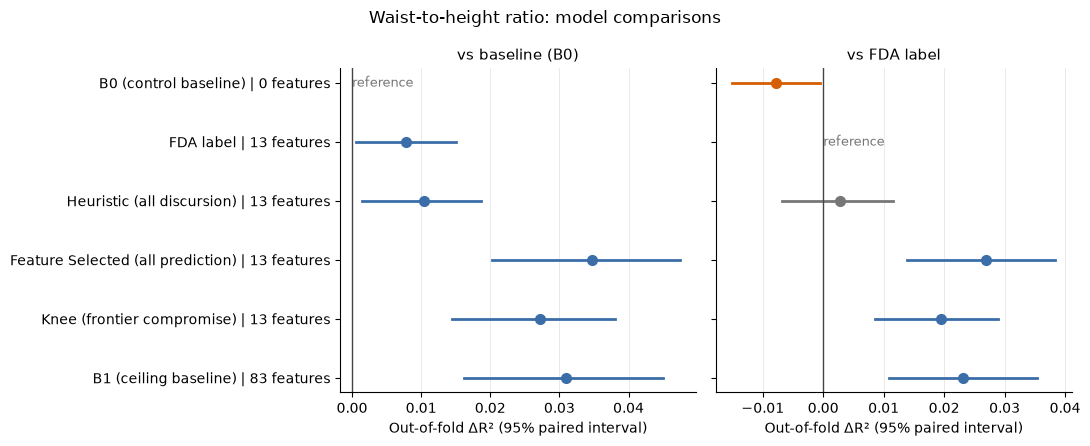

In [291]:
# Display paired intervals against reference
plot_comparisons(yw, models_w, order, "Waist-to-height ratio: model comparisons")